# AI Tools for Software Bug Detection
## Task 3 · Detector timings and fixture checks
**Baltabay Aidos and Bissen Yerkebulan**

How long do fixed AST rules and a trained lexical Naive Bayes classifier take to score Python functions? The archived run measures both on the same inputs. Twelve unlabelled functions from the Task 2 repository supply the timing workload. Eight labelled synthetic test fixtures separately check that the instrument reproduces the expected predictions. Only the fixtures have ground truth.

Use **Restart Kernel and Run All** to rebuild the summaries and figures from the recorded log. Timing collection is a separate step so reviewing the notebook preserves the original observations.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys

import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
root = next(p for p in (here, *here.parents) if (p / "src" / "collect_task3.py").is_file())
sys.path.insert(0, str(root))
from src import process_data as analysis
from src.visualize import save_figures

raw = root / "data" / "raw" / "test_run.jsonl"
meta, calls = analysis.load_run(raw)
print(f"Run {meta['run_id']} · {meta['started_utc']}")
print(f"Collector Python {meta['environment']['python']} on {meta['environment']['system']} "
      f"{meta['environment']['machine']}, seed {meta['seed']}")
print(f"Loaded {raw.relative_to(root)}: {len(calls):,} detector calls")
print("Raw SHA-256:", sha256(raw.read_bytes()).hexdigest())
display(calls.groupby(["corpus", "phase", "status"]).size().rename("calls").to_frame())

Run 9eaaf526-e5b4-4c8a-ba28-ae2c1bd9ecf3 · 2026-11-03T11:08:43.381784+00:00
Collector Python 3.12.10 on Linux aarch64, seed 42
Loaded data/raw/test_run.jsonl: 1,400 detector calls
Raw SHA-256: ef7a7fb5a6208d53768159fba07af7f2e5d20891e969d851bc27ac46b18a4685


calls
corpus     phase     status       
fixture    benchmark ok        480
           warmup    ok         80
repository benchmark ok        720
           warmup    ok        120

### 1. Separate warm-up from evaluation

Each pass visits each input once with both methods. The input order and method order use seed 42. Five complete passes warm the scorers and 30 supply measurements. The timer brackets a single scorer call. Loading, training, JSON writes and notebook analysis are outside that interval. Inspect failed attempts before selecting successful latencies. Incorrect classifications have a separate count.

In [2]:
warm = calls.loc[calls.phase.eq("warmup")]
measured = calls.loc[calls.phase.eq("benchmark")]
ok = measured.loc[measured.status.eq("ok")]
assert len(warm) + len(measured) == len(calls)
print(f"{len(warm):,} warm-up calls excluded; {len(measured):,} benchmark attempts; "
      f"{len(measured) - len(ok)} failed benchmark attempts.")
display(measured.groupby(["corpus", "method"]).agg(
    unique_inputs=("snippet_id", "nunique"), passes=("repetition", "nunique"),
    attempted_calls=("status", "size"), successful_calls=("status", lambda v: (v == "ok").sum())
))

200 warm-up calls excluded; 1,200 benchmark attempts; 0 failed benchmark attempts.


unique_inputs  passes  attempted_calls  \
corpus     method                                                   
fixture    multinomial_nb              8      30              240   
           static_rules                8      30              240   
repository multinomial_nb             12      30              360   
           static_rules               12      30              360   

                           successful_calls  
corpus     method                            
fixture    multinomial_nb               240  
           static_rules                 240  
repository multinomial_nb               360  
           static_rules                 360

### 2. Compute latency, tails and detector throughput

The median and p95/p99 summarize individual successful detector calls. The IQR rule flags unusual latencies without deleting them. Throughput divides completed calls by the time inside their scorers. A 10,000-draw percentile bootstrap with seed 42 resamples complete benchmark passes, keeping their workload composition intact. Its 95% intervals describe repeat-to-repeat variation on the same machine and fixed inputs.

In [3]:
summary, categories, delta = analysis.summarize(meta, calls)
processed = root / "data" / "processed"
analysis.write_outputs(processed, summary, categories)

cols = ["corpus", "method", "latency_p50_ms", "latency_p50_ci_low_ms",
        "latency_p50_ci_high_ms", "latency_p95_ms", "latency_p99_ms",
        "throughput_snippets_per_s", "outlier_count", "measurement_errors"]
display(summary[cols].round(5).set_index(["corpus", "method"]).T)
print("Saved data/processed/metrics_summary.csv and data/processed/fixture_categories.csv")

corpus                      repository                     fixture  \
method                    static_rules multinomial_nb static_rules   
latency_p50_ms                 0.10729        0.01510      0.01471   
latency_p50_ci_low_ms          0.09996        0.01488      0.01435   
latency_p50_ci_high_ms         0.10808        0.01542      0.01508   
latency_p95_ms                 1.21503        0.15129      0.03332   
latency_p99_ms                 1.29157        0.16030      0.03667   
throughput_snippets_per_s   5016.66963    35865.95815  52791.22610   
outlier_count                 36.00000       27.00000     17.00000   
measurement_errors             0.00000        0.00000      0.00000   

corpus                                    
method                    multinomial_nb  
latency_p50_ms                   0.00429  
latency_p50_ci_low_ms            0.00417  
latency_p50_ci_high_ms           0.00438  
latency_p95_ms                   0.00721  
latency_p99_ms                   0.01213  
throughput_snippets_per_s   205723.39632  
outlier_count                   15.00000  
measurement_errors               0.00000

Saved data/processed/metrics_summary.csv and data/processed/fixture_categories.csv


### 3. Check classifications at the snippet level

Each of the eight test fixtures contributes one prediction per method. Repeated scoring of the same snippet does not enlarge the labelled sample. For the F1 difference, the resampling unit is a whole fixture project and the same draw supplies both methods. The resulting interval checks the bootstrap procedure on four artificial groups. Real-code F1 and FPR need independent labels.

In [4]:
quality = summary.loc[summary.corpus.eq("fixture")]
display(quality[["method", "quality_n", "tp", "fp", "tn", "fn",
                 "precision", "recall", "f1", "false_positive_rate"]].set_index("method"))
display(categories)
print(f"Fixture difference (NB minus AST): {delta['delta_f1']:+.3f}; "
      f"paired 95% interval [{delta['lower']:+.3f}, {delta['upper']:+.3f}].")
print(f"Whole-project draws retained: {delta['valid_draws']:,} of {delta['requested_draws']:,}.")

,quality_n,tp,fp,tn,fn,precision,recall,f1,false_positive_rate
method,,,,,,,,,
static_rules,8.0,4.0,0.0,4.0,0.0,1.000000,1.0,1.0,0.0
multinomial_nb,8.0,4.0,2.0,2.0,0.0,0.666667,1.0,0.8,0.5


,method,category,n,tp,fp,tn,fn,precision,recall,f1,false_positive_rate
0,multinomial_nb,division_by_zero,4,2,2,0,0,0.5,1.0,0.666667,1.0
1,multinomial_nb,mutable_default,4,2,0,2,0,1.0,1.0,1.000000,0.0
2,static_rules,division_by_zero,4,2,0,2,0,1.0,1.0,1.000000,0.0
3,static_rules,mutable_default,4,2,0,2,0,1.0,1.0,1.000000,0.0


Fixture difference (NB minus AST): -0.200; paired 95% interval [-0.333, +0.000].
Whole-project draws retained: 10,000 of 10,000.


### 4. Audit the limits registered in Task 2

The limits are 100 ms p95 per method, 256 MiB whole-process peak RSS, zero measurement errors and FPR at most 0.10. The collector records shared process RSS, including both scorers and fitting. The offline notebook runs in a different process. Only the synthetic fixtures admit an FPR check.

In [5]:
display(summary[["corpus", "method", "p95_within_100ms", "fpr_within_0_10",
                 "zero_errors_pass"]].fillna("unlabelled").set_index(["corpus", "method"]))
print(f"Shared collector peak through final scored call: {meta['end']['peak_rss_mib']:.2f} MiB "
      f"(limit {meta['guardrails']['max_process_peak_rss_mib']:.0f} MiB).")
print(f"NB fitting: {meta['model_fit_ms']:.3f} ms. Errors over all phases: "
      f"{meta['end']['measurement_errors']}.")
from src.collect_task3 import verify_model
verify_model(raw, root / "models" / "task3_nb.json")

p95_within_100ms fpr_within_0_10  zero_errors_pass
corpus     method                                                            
repository static_rules                True      unlabelled              True
           multinomial_nb              True      unlabelled              True
fixture    static_rules                True            True              True
           multinomial_nb              True           False              True

Shared collector peak through final scored call: 20.83 MiB (limit 256 MiB).
NB fitting: 0.089 ms. Errors over all phases: 0.
Model replay verified for 20 inputs and 700 NB calls.


### 5. Plot and export the unlabelled workload

Figure 1 orders the twelve functions by the number of UTF-8 bytes passed to each scorer. Each point is a function's median call latency. Its 95% interval resamples repeats. Byte count is an observed input characteristic. Functions also differ in syntax and token content.

Figure 2 pools successful calls within each method. The boxes describe the spread among calls and the separate intervals describe uncertainty in the median. Both figures use the archived run.

reports/figures/fig1_latency_vs_load.pdf
reports/figures/fig1_latency_vs_load.png
reports/figures/fig2_distribution_boxplot.pdf
reports/figures/fig2_distribution_boxplot.png


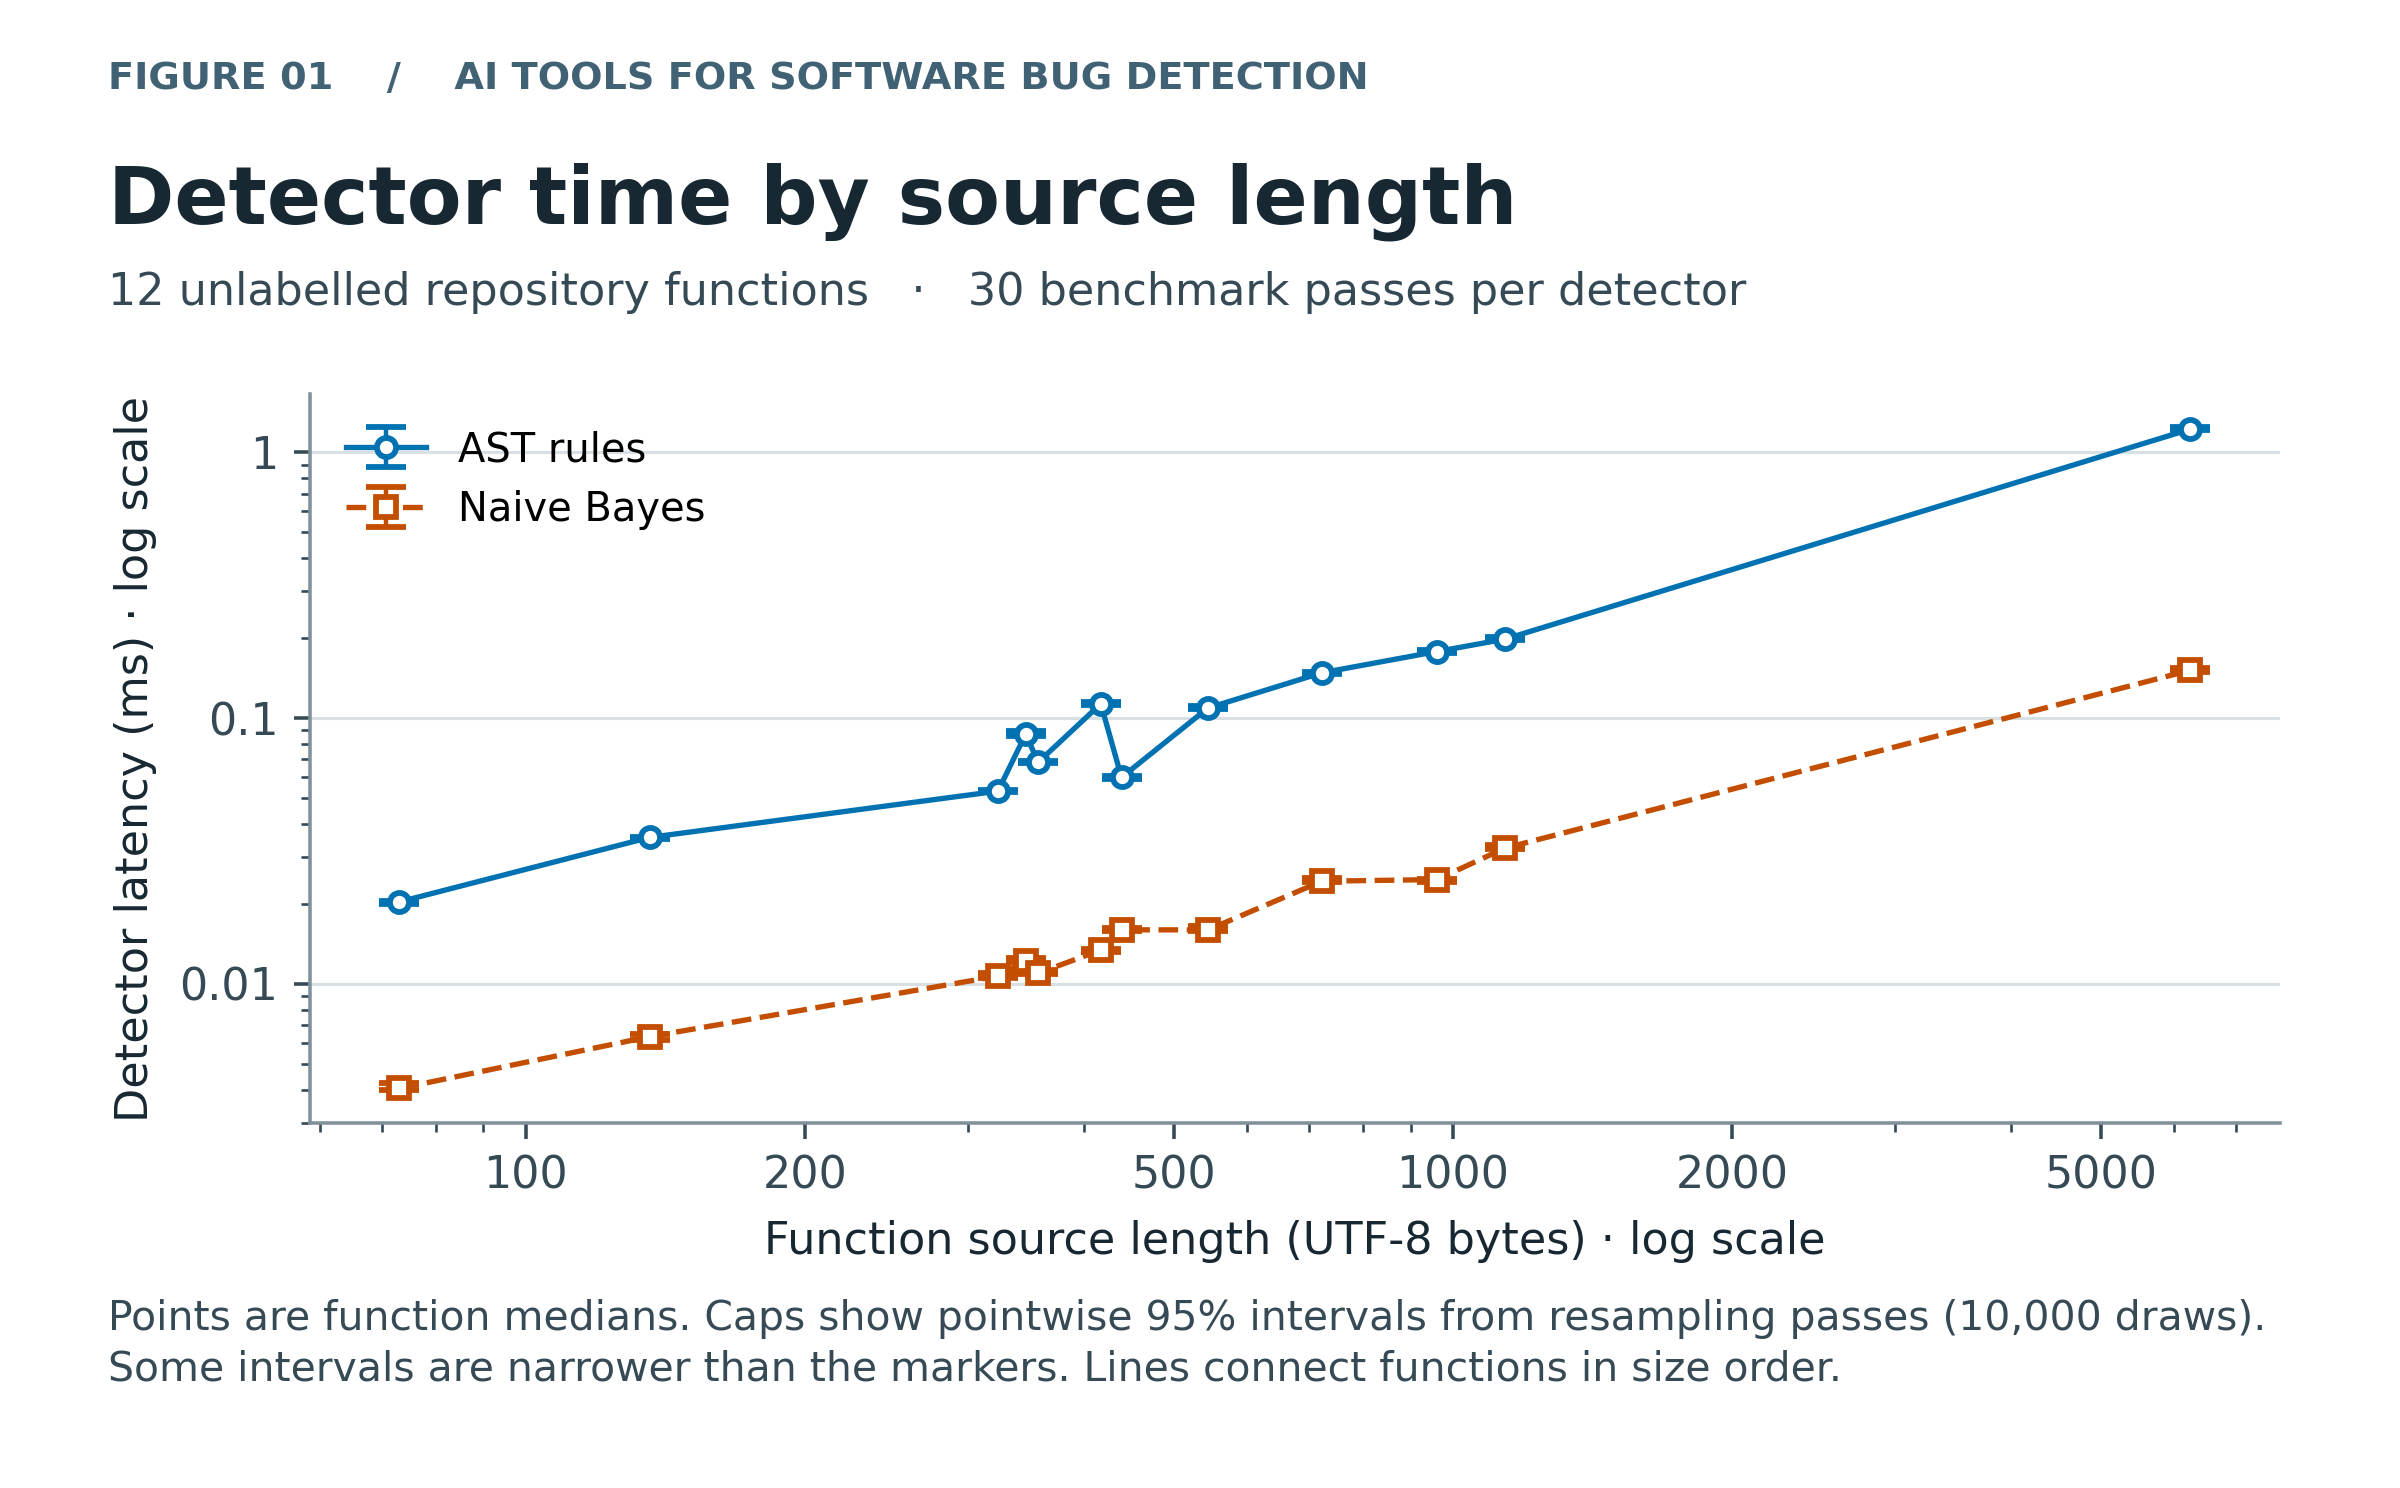

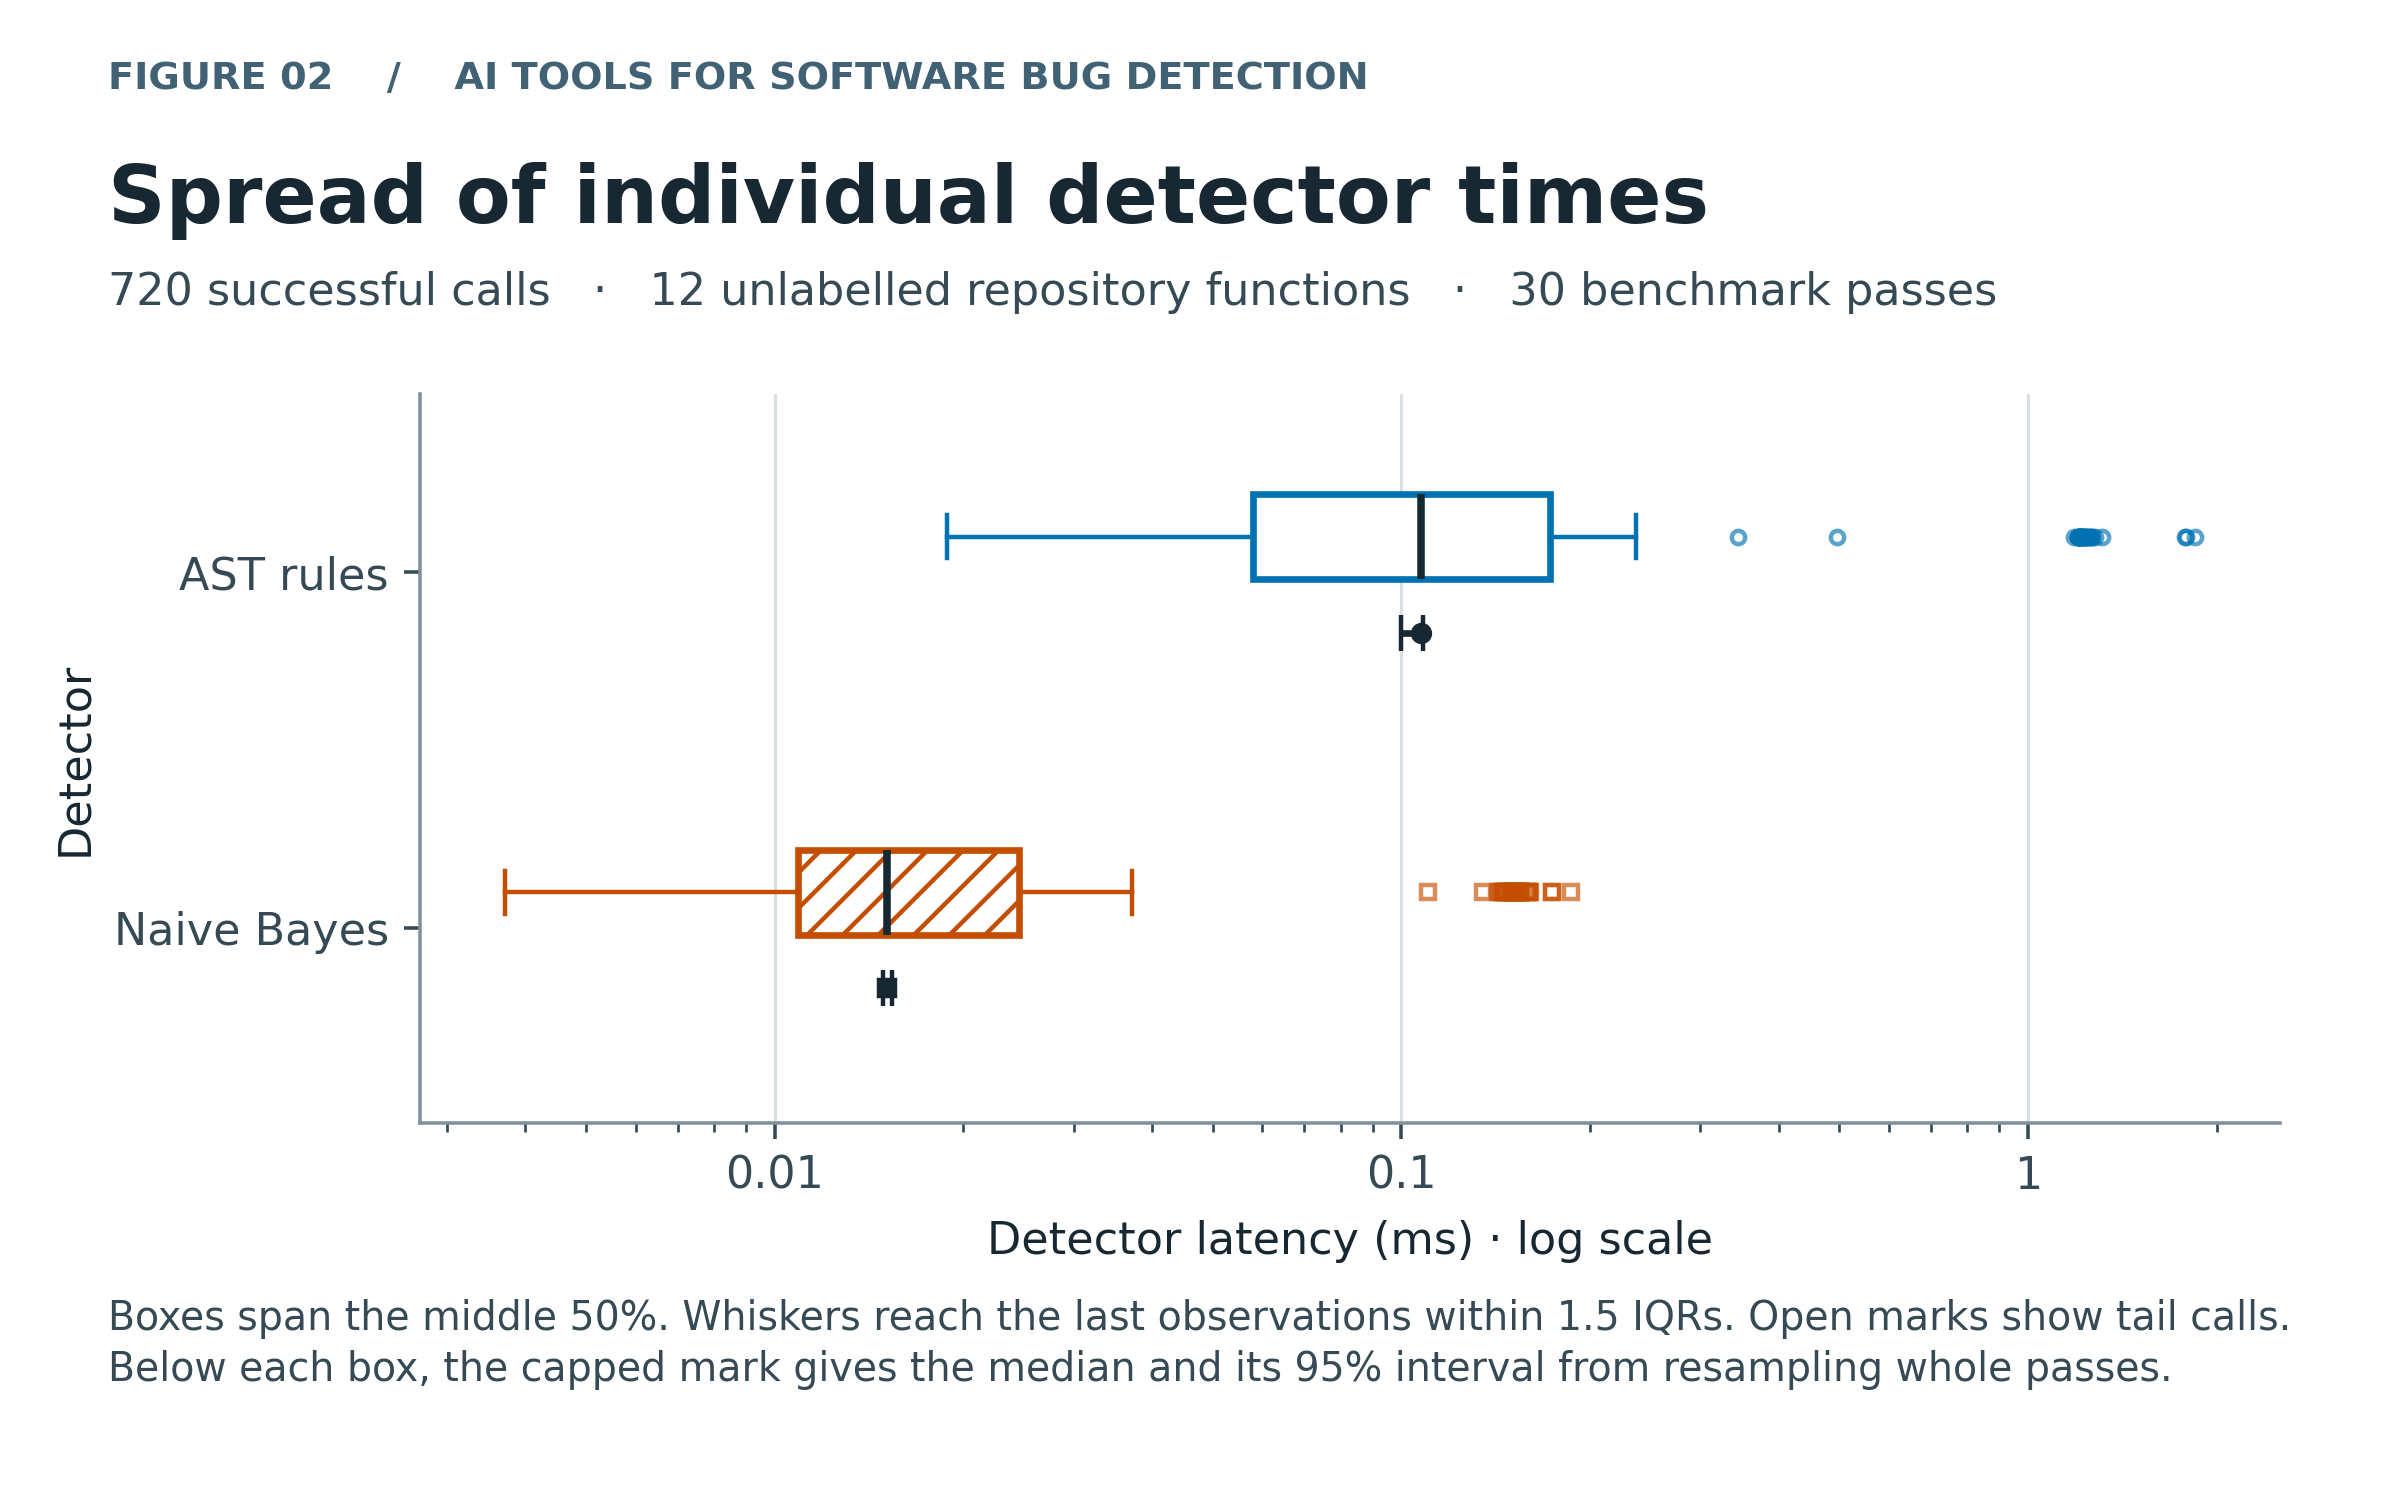

In [6]:
figures = save_figures(calls, summary, root / "reports" / "figures")
for path in figures:
    print(path.relative_to(root).as_posix())
for path in figures:
    if path.suffix == ".png":
        display(Image(filename=str(path), width=780))

### Interpretation

This run estimates the cost of scoring these inputs on the recorded host. It exercises the full quality calculation on the labelled fixtures. The Task 2 hypothesis concerns two-author-reviewed snippets from held-out projects and remains untested. The registered research protocol requires at least 50 training and 100 test snippets from at least ten held-out test projects.